# GPT-2 range merger: 8M-token subset, two shuffled passes, two-hour budget

Enable Kaggle T4 + Internet and Run All in a fresh kernel. This version starts a NEW experiment; v3 checkpoints are incompatible.

The subset contains up to **8M unique tokens** (or available training data if smaller). Two passes process up to **16M tokens**, not 16M unique tokens. Each pass reshuffles windows. The same anchor window gets a different range task on its second pass; whole batches are regrouped by shuffling. Half of schedule slots target long ranges, including 25% for L2-L11. Actual exposure is logged.

Training and periodic validation share the **120-minute budget**. A 120-second reserve is an estimate, not a hard guarantee against overrun by a single operation. Final test evaluation/setup/export are additional. Training can stop before completing pass two.

A separate AG News training holdout selects the best checkpoint by mean CE across fixed 11-, 10-, 8-, 6- and 3-block models (equivalent to geometric-mean PPL). Validate initially, every ~15 minutes, at epoch boundaries and at the end. The original ranking holdout stays separate; test sets never select checkpoints. Initial weights are eligible if training does not improve validation. Resume retains the last optimizer state; final testing uses the best validation checkpoint.

Architecture, literal `hidden loss + 0.5 * PPL`, original-weight range merging and test evaluation are unchanged. Outputs include training/validation histories, CSV metrics, PNGs, experiment_charts.pdf and validation_selection.pdf. Read README_8M_2EPOCHS.md for usage and limitations.


In [1]:
%pip install -q "transformers==4.51.3" "datasets>=3.5,<5" pandas matplotlib tabulate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 69.1 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 9.3 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 56.9 MB/s eta 0:00:00:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
"""GPT-2 weight merger: token-budgeted training, single pairs, ranked cumulative merges."""
import os
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("USE_FLAX", "0")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import copy, gc, hashlib, json, math, random, time
from pathlib import Path
from dataclasses import dataclass, asdict
from contextlib import contextmanager
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.func import functional_call
from torch.utils.checkpoint import checkpoint
from transformers import AutoTokenizer, AutoModelForCausalLM, GPT2Config
from transformers.models.gpt2.modeling_gpt2 import GPT2Block
from datasets import load_dataset
import matplotlib.pyplot as plt



## Configuration


In [3]:
@dataclass
class Config:
    model_id: str = "openai-community/gpt2"
    dataset_id: str = "fancyzhx/ag_news"
    output_dir: str = "/kaggle/working/gpt2_range_merger_v4_8m_2epochs"
    seed: int = 42
    train_minutes: float = 120.0  # Includes training validation; final test evaluation is separate.
    train_epochs: int = 2
    validate_every_minutes: float = 15.0
    validation_tokens: int = 4096
    final_validation_reserve_seconds: float = 120.0
    max_train_tokens: int = 8_000_000  # Unique-subset cap; two passes process up to 16M tokens.
    train_seq_len: int = 256
    train_batch_size: int = 2
    learning_rate: float = 1e-4
    weight_decay: float = 0.01
    grad_clip: float = 1.0
    cosine_loss_weight: float = 0.1  # Set 0.0 for pure hidden-state MSE.
    checkpoint_every: int = 200
    eval_context: int = 512
    eval_stride: int = 256
    rank_tokens: int = 4096
    test_tokens: int = 8192
    save_final_model: bool = True
    # Six GPT-2 Small-style blocks; weight patch encoders/decoders replace text embeddings.
    merger_d_model: int = 768
    merger_heads: int = 12
    ppl_loss_weight: float = 0.5
    merger_dropout: float = 0.0
    square_patch_h: int = 32
    square_patch_w: int = 32
    fc_patch_h: int = 32
    fc_patch_w: int = 128
    proj_patch_h: int = 128
    proj_patch_w: int = 32

CFG = Config()
assert 0 < CFG.train_minutes <= 120
assert CFG.train_epochs >= 1 and CFG.validate_every_minutes > 0
assert CFG.train_batch_size > 0 and CFG.train_seq_len >= 2
assert 0 < CFG.eval_stride < CFG.eval_context <= 1024
OUTDIR = Path(CFG.output_dir)
OUTDIR.mkdir(parents=True, exist_ok=True)
(OUTDIR / "plots").mkdir(exist_ok=True)
DEVICE = torch.device("cuda:0")
if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU T4 and Internet in Kaggle settings.")
if torch.is_inference_mode_enabled():
    raise RuntimeError("Run outside torch.inference_mode().")
torch.set_grad_enabled(True)
torch.backends.mha.set_fastpath_enabled(False)
random.seed(CFG.seed); np.random.seed(CFG.seed); torch.manual_seed(CFG.seed)
torch.cuda.manual_seed_all(CFG.seed)
print("GPU:", torch.cuda.get_device_name(0))

def atomic_json(value, path):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(value, indent=2), encoding="utf-8")
    temp.replace(path)

def atomic_torch(value, path):
    temp = path.with_suffix(".tmp")
    torch.save(value, temp)
    temp.replace(path)

def weight_hash(module):
    digest = hashlib.sha256()
    for name, value in module.named_parameters():
        digest.update(name.encode())
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()



GPU: Tesla T4


## Merger architecture


In [4]:


def patchify_matrix(w: torch.Tensor, ph: int, pw: int):
    assert w.ndim == 2
    H, W = w.shape
    assert H % ph == 0 and W % pw == 0, (tuple(w.shape), ph, pw)
    gh, gw = H // ph, W // pw
    patches = (
        w.reshape(gh, ph, gw, pw)
         .permute(0, 2, 1, 3)
         .contiguous()
         .reshape(gh * gw, ph * pw)
    )
    return patches, gh, gw

def unpatchify_matrix(patches: torch.Tensor, gh: int, gw: int, ph: int, pw: int):
    return (
        patches.reshape(gh, gw, ph, pw)
               .permute(0, 2, 1, 3)
               .contiguous()
               .reshape(gh * ph, gw * pw)
    )

class RangeWeightMerger(nn.Module):
    """Six GPT-2 blocks over layer-major matrix-summary tokens, then six queries.

    Patch pooling bounds attention cost. The decoder retains per-patch features;
    this is a weight hypernetwork, not a text GPT-2 or full weight-token attention.
    """
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        d = cfg.merger_d_model
        self.encoders = nn.ModuleDict({k: nn.Linear(h*w, d) for k,(h,w) in self.shapes().items()})
        self.decoders = nn.ModuleDict({k: nn.Linear(d, h*w) for k,(h,w) in self.shapes().items()})
        self.row_embed = nn.Embedding(24, d)
        self.col_embed = nn.Embedding(24, d)
        self.layer_embed = nn.Embedding(12, d)
        self.type_embed = nn.Embedding(6, d)
        self.sequence_embed = nn.Embedding(66, d)
        self.query = nn.Parameter(torch.randn(6, d)*0.02)
        config = GPT2Config(n_embd=d, n_head=cfg.merger_heads, n_layer=6,
            n_inner=4*d, n_positions=66, activation_function="gelu_new",
            resid_pdrop=0.0, attn_pdrop=0.0, embd_pdrop=0.0, use_cache=False)
        config._attn_implementation = "eager"
        self.blocks = nn.ModuleList([GPT2Block(config, layer_idx=i) for i in range(6)])
        self.final_norm = nn.LayerNorm(d, eps=config.layer_norm_epsilon)
        self.fuse = nn.Sequential(nn.Linear(2*d,d), nn.GELU(), nn.LayerNorm(d))
        self.mix = nn.Linear(d, 10)
        for head in list(self.decoders.values()) + [self.mix]:
            nn.init.zeros_(head.weight); nn.init.zeros_(head.bias)

    def shapes(self):
        c = self.cfg
        return dict(square=(c.square_patch_h,c.square_patch_w),
                    fc=(c.fc_patch_h,c.fc_patch_w), proj=(c.proj_patch_h,c.proj_patch_w))

    def forward(self, matrices, layer_ids):
        # matrices: six [range_length, rows, columns] tensors, all ORIGINAL weights.
        kinds = ["square"]*4 + ["fc","proj"]
        features, patches, scales, grids = [], [], [], []
        for kind, weights in zip(kinds, matrices):
            ph,pw = self.shapes()[kind]
            scale = weights.float().square().mean().add(1e-12).sqrt().detach()
            p = []
            for w in weights:
                part,gh,gw = patchify_matrix(w/scale,ph,pw); p.append(part)
            p = torch.stack(p)
            rows = torch.arange(gh,device=p.device).repeat_interleave(gw)
            cols = torch.arange(gw,device=p.device).repeat(gh)
            z = F.gelu(self.encoders[kind](p) + self.row_embed(rows) + self.col_embed(cols))
            features.append(z); patches.append(p); scales.append(scale); grids.append((gh,gw))
        # Each original layer contributes Q,K,V,O,FC,PROJ in that order.
        summaries = torch.stack([z.mean(1) for z in features],dim=1)
        types = self.type_embed(torch.arange(6,device=layer_ids.device))
        summaries = summaries + self.layer_embed(layer_ids)[:,None,:] + types[None,:,:]
        tokens = torch.cat([summaries.flatten(0,1), self.query+types],dim=0)
        tokens = (tokens+self.sequence_embed(torch.arange(len(tokens),device=tokens.device))).unsqueeze(0)
        for block in self.blocks:
            tokens = block(tokens,use_cache=False)[0]
        queries = self.final_norm(tokens)[0,-6:]
        outputs = []
        for i,(kind,z,p,scale,(gh,gw)) in enumerate(zip(kinds,features,patches,scales,grids)):
            q = queries[i]
            mixture = self.mix(q)[:len(layer_ids)].float().softmax(0)
            base = (p * mixture[:,None,None]).sum(0)
            local = (z * mixture[:,None,None]).sum(0)
            fused = self.fuse(torch.cat([local,q.expand_as(local)],dim=-1))
            delta = 0.1*torch.tanh(self.decoders[kind](fused))
            ph,pw = self.shapes()[kind]
            outputs.append(unpatchify_matrix(base+delta,gh,gw,ph,pw)*scale)
        return tuple(outputs)

def validate_ranges(ranges):
    ranges = sorted(tuple(r) for r in ranges)
    previous = 1
    for start,end in ranges:
        if not (2 <= start < end <= 11) or start <= previous:
            raise ValueError("Use disjoint inclusive ranges within L2..L11, each >=2 blocks.")
        previous = end
    return ranges

def groups_from_ranges(ranges):
    lookup = dict(validate_ranges(ranges))
    groups, layer = [], 1
    while layer <= 12:
        end = lookup.get(layer,layer)
        groups.append(list(range(layer,end+1))); layer = end+1
    return groups

def build_range_params(merger, start, end):
    validate_ranges([(start,end)])
    source = [dict(b.named_parameters()) for b in ORIGINAL_BLOCKS[start-1:end]]
    streams = []
    for i in range(3):
        streams.append(torch.stack([p["attn.c_attn.weight"].chunk(3,dim=1)[i] for p in source]))
    for name in ["attn.c_proj.weight","mlp.c_fc.weight","mlp.c_proj.weight"]:
        streams.append(torch.stack([p[name] for p in source]))
    ids = torch.arange(start-1,end,device=DEVICE)
    def generate(*weights): return merger(weights,ids)
    # Checkpoint the entire hypernetwork; frozen input weights still allow parameter grads.
    result = checkpoint(generate,*streams,use_reentrant=False) if merger.training else generate(*streams)
    params = {name: torch.stack([p[name] for p in source]).mean(0) for name in source[0]
              if name not in {"attn.c_attn.weight","attn.c_proj.weight","mlp.c_fc.weight","mlp.c_proj.weight"}}
    params.update({"attn.c_attn.weight":torch.cat(result[:3],dim=1),
        "attn.c_proj.weight":result[3],"mlp.c_fc.weight":result[4],"mlp.c_proj.weight":result[5]})
    assert set(params) == EXPECTED_BLOCK_PARAM_NAMES
    return params

def ranges_for_step(step):
    rng=random.Random(CFG.seed+step)
    slot=step%40
    if slot<10: return [(2,11)]  # 25% full interior range.
    if slot<20:
        length=rng.randint(6,9)  # 25% other long ranges.
    elif slot<30:
        length=rng.randint(3,5)  # 25% medium ranges.
    elif slot<35:
        length=2  # 12.5% dedicated pairs; multi-range plans add further pairs.
    else:
        groups=[[i] for i in range(1,13)]
        for edge in rng.sample(list(range(2,11)),rng.randint(2,7)):
            _,groups=union_plan(groups,edge)
        return [(g[0],g[-1]) for g in groups if len(g)>1]
    start=rng.randint(2,12-length)
    return [(start,start+length-1)]

def hidden_reconstruction_loss(prediction,target):
    mse = F.mse_loss(prediction.float(),target.float())
    cosine = 1-F.cosine_similarity(prediction.float(),target.float(),dim=-1).mean()
    return mse+CFG.cosine_loss_weight*cosine,mse.detach(),cosine.detach()

def training_objective(batch,ranges):
    with torch.no_grad():
        states = model.transformer(batch,use_cache=False,output_hidden_states=True,
                                   return_dict=True).hidden_states
    generated = {a:build_range_params(merger,a,b) for a,b in ranges}
    terms,mses,cosines = [],[],[]
    for a,b in ranges:
        predicted = functional_call(ORIGINAL_BLOCKS[a-1],generated[a],
                                    (states[a-1],),dict(use_cache=False))[0]
        term,mse,cosine = hidden_reconstruction_loss(predicted,states[b])
        terms.append(term); mses.append(mse); cosines.append(cosine)
    hidden = torch.stack(terms).mean()
    # Compose ALL requested replacements in one student; preserve gradient through
    # the frozen suffix blocks and LM head to every generated matrix.
    h = states[0]
    for group in groups_from_ranges(ranges):
        a = group[0]
        block = ORIGINAL_BLOCKS[a-1]
        if len(group)>1:
            h = functional_call(block,generated[a],(h,),dict(use_cache=False))[0]
        else:
            def apply(x, block=block): return block(x,use_cache=False)[0]
            h = checkpoint(apply,h,use_reentrant=False) if h.requires_grad else apply(h)
    h = model.transformer.ln_f(h)
    flat = h[:,:-1].reshape(-1,h.shape[-1])
    labels = batch[:,1:].reshape(-1)
    def ce_chunk(x,y):
        return F.cross_entropy(model.lm_head(x).float(),y,reduction="sum")
    nll = sum(checkpoint(ce_chunk,flat[i:i+64],labels[i:i+64],use_reentrant=False)
              for i in range(0,len(labels),64))/len(labels)
    ppl = nll.exp()  # Literal PPL, intentionally NOT log-PPL/CE or a clipped surrogate.
    loss = hidden + CFG.ppl_loss_weight*ppl
    return loss,hidden,torch.stack(mses).mean(),torch.stack(cosines).mean(),nll,ppl


EXPECTED_BLOCK_PARAM_NAMES = {
    "attn.c_attn.weight",
    "attn.c_attn.bias",
    "attn.c_proj.weight",
    "attn.c_proj.bias",
    "ln_1.weight",
    "ln_1.bias",
    "mlp.c_fc.weight",
    "mlp.c_fc.bias",
    "mlp.c_proj.weight",
    "mlp.c_proj.bias",
    "ln_2.weight",
    "ln_2.bias",
}

def get_blocks(model):
    if not hasattr(model, "transformer") or not hasattr(model.transformer, "h"):
        raise TypeError("Expected Hugging Face GPT-style model with transformer.h")
    return list(model.transformer.h)

def validate_block_shape(block, model_id):
    p = dict(block.named_parameters())
    names = set(p)
    if names != EXPECTED_BLOCK_PARAM_NAMES:
        raise RuntimeError(
            f"{model_id}: incompatible block parameter names.\n"
            f"Missing: {EXPECTED_BLOCK_PARAM_NAMES - names}\n"
            f"Extra: {names - EXPECTED_BLOCK_PARAM_NAMES}"
        )

    required_shapes = {
        "attn.c_attn.weight": (768, 2304),
        "attn.c_proj.weight": (768, 768),
        "mlp.c_fc.weight": (768, 3072),
        "mlp.c_proj.weight": (3072, 768),
    }
    for name, shape in required_shapes.items():
        if tuple(p[name].shape) != shape:
            raise RuntimeError(
                f"{model_id}: {name} has {tuple(p[name].shape)}, expected {shape}"
            )



## Dataset preparation and frozen GPT-2


In [5]:
tokenizer = AutoTokenizer.from_pretrained(CFG.model_id)
model = AutoModelForCausalLM.from_pretrained(CFG.model_id, attn_implementation="eager",
                                           torch_dtype=torch.float32).to(DEVICE)
model.eval().requires_grad_(False)
ORIGINAL_BLOCKS = list(model.transformer.h)
assert len(ORIGINAL_BLOCKS) == 12 and model.config.model_type == "gpt2"
validate_block_shape(ORIGINAL_BLOCKS[0], CFG.model_id)
ORIGINAL_HASH = weight_hash(model)
BASE_PARAMS = sum(p.numel() for p in model.parameters())
# Zero-based left indices correspond to L2-L3, ..., L10-L11.
ALLOWED_PAIRS = list(range(1, 10))

news = load_dataset(CFG.dataset_id, split="train")
split = news.train_test_split(test_size=0.02, seed=CFG.seed, shuffle=True)
train_rows, rank_rows = split["train"], split["test"]
selection_split=train_rows.train_test_split(test_size=0.02,seed=CFG.seed+1,shuffle=True)
train_rows,val_rows=selection_split["train"],selection_split["test"]

def encode_rows(rows, field, token_cap=None, separator=None):
    """CPU token stream; tokenize bounded batches, stop at a declared cap."""
    separator = [tokenizer.eos_token_id] if separator is None else separator
    chunks, count = [], 0
    for start in range(0, len(rows), 128):
        texts = [str(t).strip() for t in rows[start:start+128][field] if t is not None and str(t).strip()]
        for ids in tokenizer(texts, add_special_tokens=False, truncation=False)["input_ids"] if texts else []:
            ids = ids + separator
            if token_cap is not None:
                ids = ids[:max(token_cap-count, 0)]
            chunks.extend(ids); count += len(ids)
            if token_cap is not None and count >= token_cap:
                return torch.tensor(chunks, dtype=torch.long)
    return torch.tensor(chunks, dtype=torch.long)

TRAIN_IDS = encode_rows(train_rows, "text", CFG.max_train_tokens)
RANK_IDS = encode_rows(rank_rows, "text", CFG.rank_tokens)
VAL_IDS = encode_rows(val_rows,"text",CFG.validation_tokens)
assert len(VAL_IDS)>=2
if len(TRAIN_IDS) < CFG.train_seq_len * CFG.train_batch_size or len(RANK_IDS) < 2:
    raise RuntimeError("Insufficient training/ranking data.")
MANIFEST = dict(config=asdict(CFG), model_sha256=ORIGINAL_HASH,
    train_fingerprint=train_rows._fingerprint, validation_fingerprint=rank_rows._fingerprint,
    selection_fingerprint=val_rows._fingerprint,
    selection_token_sha256=hashlib.sha256(VAL_IDS.numpy().tobytes()).hexdigest(),
    validation_plans={"11_blocks":[[2,3]],"10_blocks":[[4,6]],"8_blocks":[[2,4],[7,9]],"6_blocks":[[2,8]],"3_blocks":[[2,11]]},
    train_token_sha256=hashlib.sha256(TRAIN_IDS.numpy().tobytes()).hexdigest(),
    validation_token_sha256=hashlib.sha256(RANK_IDS.numpy().tobytes()).hexdigest(),
    input_tokens_available=len(TRAIN_IDS), allowed_pairs=[f"L{i+1}-L{i+2}" for i in ALLOWED_PAIRS],
    ranking_split="AG News held-out 2% of TRAIN", objective="mean range hidden MSE + 0.1 cosine + 0.5 exp(student next-token CE)",
    code_version="gpt2-range-merger-v4-8m-2epochs")
manifest_path = OUTDIR / "manifest.json"
if manifest_path.exists() and json.loads(manifest_path.read_text()) != MANIFEST:
    raise RuntimeError("Settings/data changed. Choose a new output_dir.")
atomic_json(MANIFEST, manifest_path)
print("Prepared fresh training input tokens:", len(TRAIN_IDS))

@contextmanager
def use_blocks(blocks):
    old_blocks, old_layers = model.transformer.h, model.config.n_layer
    model.transformer.h = nn.ModuleList(blocks)
    model.config.n_layer = len(blocks)
    try:
        yield
    finally:
        model.transformer.h, model.config.n_layer = old_blocks, old_layers

def union_plan(groups, left_layer):
    """Resolve an original edge Lk-L(k+1) to two adjacent current groups."""
    if not 2 <= left_layer <= 10: raise ValueError("Endpoint layers cannot be merged.")
    left = next(i for i,g in enumerate(groups) if left_layer in g)
    right = next(i for i,g in enumerate(groups) if left_layer+1 in g)
    if right != left+1: raise ValueError("Edge was already merged or groups are nonadjacent.")
    new = groups[:left] + [groups[left]+groups[right]] + groups[right+1:]
    assert new[0] == [1] and new[-1] == [12]
    return left, new

merger = RangeWeightMerger(CFG).to(DEVICE)
frozen_path, resume_path = OUTDIR / "frozen_merger.pt", OUTDIR / "merger_resume.pt"

@torch.inference_mode()
def score(ids, example_count=8):
    if len(ids) < 2: raise ValueError("Too few evaluation tokens.")
    total_nll = 0.0; count = top1 = top5 = 0
    previous_end = 0
    examples = []
    for begin in range(0, len(ids), CFG.eval_stride):
        end = min(begin + CFG.eval_context, len(ids))
        newly_scored = end - previous_end
        batch = ids[begin:end].unsqueeze(0).to(DEVICE)
        logits = model(input_ids=batch, use_cache=False, return_dict=True).logits[0]
        # Target positions [first, end-begin), each once, with at least one context token.
        first = max(1, len(batch[0]) - newly_scored)
        for pos in range(first, len(batch[0]), 64):
            stop = min(pos + 64, len(batch[0]))
            prediction_logits = logits[pos-1:stop-1].float()
            labels = batch[0, pos:stop]
            total_nll += float(F.cross_entropy(prediction_logits, labels, reduction="sum"))
            indices = prediction_logits.topk(5, dim=-1).indices
            top1 += int((indices[:,0] == labels).sum())
            top5 += int((indices == labels[:,None]).any(dim=-1).sum())
            count += len(labels)
            for offset in range(min(len(labels), example_count-len(examples))):
                local = pos + offset
                examples.append(dict(target_position=begin+local,
                    context=tokenizer.decode(batch[0,max(0,local-24):local].tolist()),
                    actual_next_token=tokenizer.decode([int(labels[offset])]),
                    predicted_next_token=tokenizer.decode([int(indices[offset,0])]),
                    actual_id=int(labels[offset]), predicted_id=int(indices[offset,0])))
        del logits, batch
        previous_end = end
        if end == len(ids): break
    assert count == len(ids)-1, (count, len(ids))
    ce = total_nll/count
    return dict(ce=ce, ppl=math.exp(ce) if ce < 709 else float("inf"),
                top1_accuracy=top1/count, top5_accuracy=top5/count, scored_tokens=count), examples


@torch.no_grad()
def generated_block(start,end):
    params = build_range_params(merger,start,end)
    output = copy.deepcopy(ORIGINAL_BLOCKS[start-1])
    loaded = output.load_state_dict(params,strict=False)
    if loaded.unexpected_keys or set(dict(output.named_parameters())).intersection(loaded.missing_keys):
        raise RuntimeError("Incomplete generated block.")
    return output.eval().requires_grad_(False)

def blocks_for_groups(groups):
    return [ORIGINAL_BLOCKS[g[0]-1] if len(g)==1 else generated_block(g[0],g[-1]) for g in groups]

def merge_ranges(ranges):
    """One-based inclusive ranges, e.g. [(2,3),(5,6),(9,11)]. Original weights only."""
    groups = groups_from_ranges(ranges)
    return blocks_for_groups(groups),groups

VALIDATION_PLANS = {
    "11_blocks": [(2,3)], "10_blocks": [(4,6)],
    "8_blocks": [(2,4),(7,9)], "6_blocks": [(2,8)], "3_blocks": [(2,11)],
}
best_path = OUTDIR / "best_merger.pt"

def epoch_order(epoch, nblocks):
    return torch.randperm(nblocks,generator=torch.Generator().manual_seed(CFG.seed+epoch)).tolist()

def ranges_for_batch(epoch, indices):
    # Anchor the task to the first window, then force a different task on its next pass.
    key = indices[0]
    old = ranges_for_step(key)
    for e in range(1,epoch+1):
        step = key + e*104729
        new = ranges_for_step(step)
        while new == old:
            step += 1; new = ranges_for_step(step)
        old = new
    return old

@torch.no_grad()
def validate_merger():
    was_training = merger.training
    merger.eval()
    results = {}
    try:
        for name,ranges in VALIDATION_PLANS.items():
            blocks,groups = merge_ranges(ranges)
            with use_blocks(blocks):
                metrics,_ = score(VAL_IDS,example_count=0)
            results[name] = dict(ce=metrics["ce"],ppl=metrics["ppl"])
            del blocks
    finally:
        merger.train(was_training)
    # Equal weight to each compression level; equivalent to geometric-mean PPL.
    mean_ce = sum(v["ce"] for v in results.values())/len(results)
    return mean_ce,results

def train_merger():
    optimizer = torch.optim.AdamW(merger.parameters(),lr=CFG.learning_rate,
                                  weight_decay=CFG.weight_decay,foreach=False)
    scaler = torch.amp.GradScaler("cuda",init_scale=1024)
    nblocks = len(TRAIN_IDS)//CFG.train_seq_len
    updates = cursor = epoch = input_tokens = hidden_positions = 0
    previous_seconds = 0.0
    logs,validation_logs,range_counts = [],[],{}
    last_val_seconds = 0.0
    if resume_path.exists():
        saved = torch.load(resume_path,map_location="cpu",weights_only=True)
        if saved["manifest"] != MANIFEST: raise RuntimeError("Checkpoint mismatch.")
        merger.load_state_dict(saved["merger"]);optimizer.load_state_dict(saved["optimizer"])
        scaler.load_state_dict(saved["scaler"])
        updates,cursor,epoch = saved["updates"],saved["cursor"],saved["epoch"]
        input_tokens,hidden_positions = saved["input_tokens"],saved["hidden_positions"]
        previous_seconds,logs = saved["elapsed_seconds"],saved["logs"]
        validation_logs,range_counts = saved["validation_logs"],saved["range_counts"]
        last_val_seconds = saved["last_val_seconds"]
        torch.set_rng_state(saved["rng_cpu"]);torch.cuda.set_rng_state_all(saved["rng_cuda"])
        del saved
    best_score,best_update = float("inf"),None
    if best_path.exists():
        best = torch.load(best_path,map_location="cpu",weights_only=True)
        if best["manifest"] != MANIFEST:raise RuntimeError("Best-checkpoint mismatch.")
        best_score,best_update = best["mean_ce"],best["update"]
        del best
    start = time.monotonic()
    def elapsed(): return previous_seconds+time.monotonic()-start
    def save():
        atomic_torch(dict(manifest=MANIFEST,merger=merger.state_dict(),optimizer=optimizer.state_dict(),
            scaler=scaler.state_dict(),updates=updates,cursor=cursor,epoch=epoch,input_tokens=input_tokens,
            hidden_positions=hidden_positions,elapsed_seconds=elapsed(),logs=logs,range_counts=range_counts,
            validation_logs=validation_logs,last_val_seconds=last_val_seconds,
            rng_cpu=torch.get_rng_state(),rng_cuda=torch.cuda.get_rng_state_all()),resume_path)
        pd.DataFrame(logs).to_csv(OUTDIR/"merger_training.csv",index=False)
        atomic_json(validation_logs,OUTDIR/"validation_history.json")
    def validate(reason):
        nonlocal best_score,best_update,last_val_seconds
        torch.cuda.synchronize()
        score_value,details = validate_merger()
        row=dict(update=updates,epoch=epoch+cursor/nblocks,processed_input_tokens=input_tokens,
                 mean_ce=score_value,geometric_mean_ppl=math.exp(score_value),plans=details,reason=reason)
        if not math.isfinite(score_value): raise FloatingPointError("Nonfinite validation score.")
        if score_value < best_score:
            best_score,best_update = score_value,updates
            atomic_torch(dict(manifest=MANIFEST,merger=merger.state_dict(),mean_ce=best_score,
                              update=updates,validation=row),best_path)
        last_val_seconds=elapsed();row["elapsed_minutes"]=last_val_seconds/60
        validation_logs.append(row);print("Validation:",row,flush=True)
        save()
    merger.train()
    if not validation_logs: validate("initial")
    order=epoch_order(epoch,nblocks)
    retries=0;step_seconds=0.0
    stop_reason="epochs_completed"
    while epoch < CFG.train_epochs:
        # Reserve time for final validation/saving. Training validation counts in the budget.
        if elapsed()+max(CFG.final_validation_reserve_seconds,1.2*step_seconds) >= CFG.train_minutes*60:
            stop_reason="training_time_budget";break
        indices=order[cursor:cursor+CFG.train_batch_size]
        batch=torch.stack([TRAIN_IDS[i*CFG.train_seq_len:(i+1)*CFG.train_seq_len] for i in indices]).to(DEVICE)
        ranges=ranges_for_batch(epoch,indices)
        step_start=time.monotonic();optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda",dtype=torch.float16):
            loss,hidden,mse,cosine,nll,ppl=training_objective(batch,ranges)
        if not torch.isfinite(loss) or not loss.requires_grad:
            save();raise FloatingPointError("Nonfinite training loss; checkpoint saved.")
        scaler.scale(loss).backward();scaler.unscale_(optimizer)
        norm=nn.utils.clip_grad_norm_(merger.parameters(),CFG.grad_clip)
        old_scale=scaler.get_scale();scaler.step(optimizer);scaler.update()
        values=[float(t.detach()) for t in [loss,hidden,mse,cosine,nll,ppl]]
        del batch,loss,hidden,mse,cosine,nll,ppl
        if scaler.get_scale()<old_scale:
            retries+=1
            if retries>20:save();raise FloatingPointError("Repeated FP16 overflow.")
            continue
        retries=0;step_seconds=time.monotonic()-step_start
        cursor+=len(indices);updates+=1;input_tokens+=len(indices)*CFG.train_seq_len
        hidden_positions+=len(indices)*CFG.train_seq_len*len(ranges)
        for a,b in ranges:
            key=str(b-a+1);range_counts[key]=range_counts.get(key,0)+1
        if updates==1 or updates%25==0:
            row=dict(update=updates,epoch=epoch+cursor/nblocks,ranges=str(ranges),
                total_loss=values[0],reconstruction_loss=values[1],mse=values[2],cosine_distance=values[3],
                next_token_ce=values[4],train_ppl=values[5],weighted_ppl_loss=CFG.ppl_loss_weight*values[5],
                processed_input_tokens=input_tokens,unique_input_tokens=min(input_tokens,nblocks*CFG.train_seq_len),
                training_minutes=elapsed()/60,grad_norm=float(norm))
            logs.append(row);print(row,flush=True)
        end_epoch=cursor==nblocks
        if end_epoch:
            epoch+=1;cursor=0
            validate("epoch_end")
            if epoch<CFG.train_epochs:order=epoch_order(epoch,nblocks)
        elif elapsed()-last_val_seconds >= CFG.validate_every_minutes*60:
            validate("periodic")
        elif updates%CFG.checkpoint_every==0:save()
    if not updates:raise RuntimeError("No training update completed.")
    if validation_logs[-1]["update"]!=updates:validate("training_end")
    save() # Resume retains LAST optimizer/model state, not the selected earlier model.
    best=torch.load(best_path,map_location="cpu",weights_only=True)
    merger.load_state_dict(best["merger"]);del best
    summary=dict(updates=updates,processed_input_tokens=input_tokens,
        unique_input_tokens=min(input_tokens,nblocks*CFG.train_seq_len),available_input_tokens=len(TRAIN_IDS),
        completed_epochs=epoch,corpus_passes=input_tokens/(nblocks*CFG.train_seq_len),
        hidden_state_target_positions=hidden_positions,elapsed_seconds=elapsed(),
        max_budget_minutes=CFG.train_minutes,stop_reason=stop_reason,gpt2_finetuned=False,
        best_validation_update=best_update,best_validation_mean_ce=best_score,
        range_length_update_counts=range_counts,merger_parameters=sum(p.numel() for p in merger.parameters()))
    pd.DataFrame(logs).to_csv(OUTDIR/"merger_training.csv",index=False)
    atomic_json(summary,OUTDIR/"training_summary.json")
    atomic_torch(dict(merger=merger.state_dict(),manifest=MANIFEST,summary=summary),frozen_path)
    print("Training finished; selected best held-out checkpoint:",summary)


if frozen_path.exists():
    saved = torch.load(frozen_path, map_location="cpu", weights_only=True)
    if saved["manifest"] != MANIFEST:
        raise RuntimeError("Frozen merger mismatch.")
    merger.load_state_dict(saved["merger"])
    atomic_json(saved["summary"], OUTDIR / "training_summary.json")
    del saved
else:
    train_merger()
merger.eval().requires_grad_(False)
merger.zero_grad(set_to_none=True)
assert weight_hash(model) == ORIGINAL_HASH
assert not any(p.grad is not None for p in model.parameters())
MERGER_HASH = weight_hash(merger)
gc.collect(); torch.cuda.empty_cache()



tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Prepared fresh training input tokens: 6105951
Validation: {'update': 0, 'epoch': 0.0, 'processed_input_tokens': 0, 'mean_ce': 7.37022215753539, 'geometric_mean_ppl': 1587.986527033709, 'plans': {'11_blocks': {'ce': 5.441878955733936, 'ppl': 230.87558116263662}, '10_blocks': {'ce': 6.2294678032471005, 'ppl': 507.4853295701077}, '8_blocks': {'ce': 7.65117680848882, 'ppl': 2103.1191021217223}, '6_blocks': {'ce': 9.374788091005133, 'ppl': 11787.419421672977}, '3_blocks': {'ce': 8.15379912920196, 'ppl': 3476.5619158443787}}, 'reason': 'initial', 'elapsed_minutes': 0.07003086660000027}
{'update': 1, 'epoch': 8.385392646010649e-05, 'ranges': '[(2, 11)]', 'total_loss': 2084.96435546875, 'reconstruction_loss': 120.42684936523438, 'mse': 120.32217407226562, 'cosine_distance': 1.0467252731323242, 'next_token_ce': 8.276159286499023, 'train_ppl': 3929.074951171875, 'weighted_ppl_loss': 1964.5374755859375, 'processed_input_tokens': 512, 'unique_input_tokens': 512, 'training_minutes': 0.1010998422000

## Evaluation: held-out in-domain data and datasets unused by merger training


In [6]:
TEST_IDS = {
    "ag_news_test": encode_rows(load_dataset(CFG.dataset_id, split="test"), "text", CFG.test_tokens),
    "wikitext2_test": encode_rows(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test"),
                                  "text", CFG.test_tokens),
    "ptb_test": encode_rows(load_dataset("text", data_files={"test":
        "https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb.test.txt"}, split="test"),
        "text", CFG.test_tokens),
}
atomic_json({key:dict(tokens=len(value), sha256=hashlib.sha256(value.numpy().tobytes()).hexdigest())
             for key,value in TEST_IDS.items()}, OUTDIR / "evaluation_data.json")

def group_label(groups):
    return " | ".join("L"+"-L".join(map(str, group)) for group in groups)

rows, example_rows = [], []
def evaluate_variant(name, phase, groups, rank=None, selected_edge=""):
    metrics, _ = score(RANK_IDS, example_count=0)
    nparams = sum(p.numel() for p in model.parameters())
    common = dict(variant=name, phase=phase, rank=rank, selected_edge=selected_edge,
        groups=group_label(groups), layers=len(groups), parameters=nparams,
        parameters_removed=BASE_PARAMS-nparams, parameter_reduction_percent=100*(1-nparams/BASE_PARAMS),
        fp32_parameter_mib=nparams*4/1024**2, validation_ppl=metrics["ppl"])
    for dataset, ids in TEST_IDS.items():
        metrics_test, examples = score(ids)
        rows.append(dict(**common, dataset=dataset, **metrics_test))
        example_rows.extend(dict(variant=name, dataset=dataset, **example) for example in examples)
        print(name, dataset, "PPL", round(metrics_test["ppl"],3), "reduction", round(common["parameter_reduction_percent"],2), flush=True)
    pd.DataFrame(rows).to_csv(OUTDIR / "metrics_partial.csv", index=False)
    return common



README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

## Original model and nine independent single-pair experiments


In [7]:
original_groups = [[i] for i in range(1,13)]
evaluate_variant("original_gpt2", "baseline", original_groups)
single_scores = []
for pair in ALLOWED_PAIRS:
    layer = pair + 1
    index, groups = union_plan(original_groups, layer)
    block = generated_block(layer,layer+1)
    blocks = ORIGINAL_BLOCKS[:pair]+[block]+ORIGINAL_BLOCKS[pair+2:]
    with use_blocks(blocks):
        summary = evaluate_variant(f"single_L{layer}-L{layer+1}", "single", groups,
                                   selected_edge=f"L{layer}-L{layer+1}")
    single_scores.append(dict(left_layer=layer, pair=f"L{layer}-L{layer+1}",
                              validation_ppl=summary["validation_ppl"]))
    del block, blocks

ranking = pd.DataFrame(single_scores).sort_values(["validation_ppl","left_layer"]).reset_index(drop=True)
ranking.insert(0,"rank",range(1,len(ranking)+1))
ranking.to_csv(OUTDIR / "single_pair_ranking.csv", index=False)
print("Fixed ranking from held-out AG News validation:")
print(ranking.to_string(index=False))



original_gpt2 ag_news_test PPL 51.802 reduction 0.0
original_gpt2 wikitext2_test PPL 47.64 reduction 0.0
original_gpt2 ptb_test PPL 123.656 reduction 0.0
single_L2-L3 ag_news_test PPL 39.677 reduction 5.7
single_L2-L3 wikitext2_test PPL 51.266 reduction 5.7
single_L2-L3 ptb_test PPL 114.132 reduction 5.7
single_L3-L4 ag_news_test PPL 37.4 reduction 5.7
single_L3-L4 wikitext2_test PPL 53.848 reduction 5.7
single_L3-L4 ptb_test PPL 124.916 reduction 5.7
single_L4-L5 ag_news_test PPL 36.15 reduction 5.7
single_L4-L5 wikitext2_test PPL 53.822 reduction 5.7
single_L4-L5 ptb_test PPL 131.305 reduction 5.7
single_L5-L6 ag_news_test PPL 35.993 reduction 5.7
single_L5-L6 wikitext2_test PPL 57.815 reduction 5.7
single_L5-L6 ptb_test PPL 133.236 reduction 5.7
single_L6-L7 ag_news_test PPL 37.299 reduction 5.7
single_L6-L7 wikitext2_test PPL 57.973 reduction 5.7
single_L6-L7 ptb_test PPL 153.991 reduction 5.7
single_L7-L8 ag_news_test PPL 37.575 reduction 5.7
single_L7-L8 wikitext2_test PPL 54.96 

## Cumulative compression: start from original GPT-2, apply each ranked edge once


In [8]:
groups = copy.deepcopy(original_groups)
current_blocks = ORIGINAL_BLOCKS.copy()
for stage, record in enumerate(ranking.to_dict("records"), start=1):
    index, new_groups = union_plan(groups, record["left_layer"])
    # Discard prior generated blocks; every range is rebuilt from ORIGINAL_BLOCKS.
    current_blocks = blocks_for_groups(new_groups)
    groups = new_groups
    with use_blocks(current_blocks):
        evaluate_variant(f"cumulative_{stage:02d}", "cumulative", groups,
                         rank=stage, selected_edge=record["pair"])
    print("Stage", stage, group_label(groups))
assert groups == [[1],list(range(2,12)),[12]]
if CFG.save_final_model:
    with use_blocks(current_blocks):
        model.save_pretrained(OUTDIR / "final_3block_gpt2", safe_serialization=True)
        tokenizer.save_pretrained(OUTDIR / "final_3block_gpt2")
    atomic_json(groups, OUTDIR / "final_groups.json")



cumulative_01 ag_news_test PPL 35.993 reduction 5.7
cumulative_01 wikitext2_test PPL 57.815 reduction 5.7
cumulative_01 ptb_test PPL 133.236 reduction 5.7
Stage 1 L1 | L2 | L3 | L4 | L5-L6 | L7 | L8 | L9 | L10 | L11 | L12
cumulative_02 ag_news_test PPL 41.495 reduction 11.39
cumulative_02 wikitext2_test PPL 70.041 reduction 11.39
cumulative_02 ptb_test PPL 173.381 reduction 11.39
Stage 2 L1 | L2 | L3 | L4-L5-L6 | L7 | L8 | L9 | L10 | L11 | L12
cumulative_03 ag_news_test PPL 49.259 reduction 17.09
cumulative_03 wikitext2_test PPL 91.664 reduction 17.09
cumulative_03 ptb_test PPL 230.81 reduction 17.09
Stage 3 L1 | L2 | L3 | L4-L5-L6-L7 | L8 | L9 | L10 | L11 | L12
cumulative_04 ag_news_test PPL 60.638 reduction 22.78
cumulative_04 wikitext2_test PPL 128.324 reduction 22.78
cumulative_04 ptb_test PPL 306.991 reduction 22.78
Stage 4 L1 | L2 | L3 | L4-L5-L6-L7-L8 | L9 | L10 | L11 | L12
cumulative_05 ag_news_test PPL 79.455 reduction 28.48
cumulative_05 wikitext2_test PPL 183.69 reduction 28

## Comparisons, per-dataset rankings, compression plots, and report


In [9]:
frame = pd.DataFrame(rows)
baseline = frame[frame.phase=="baseline"][["dataset","ppl","ce","top1_accuracy","top5_accuracy"]].rename(
    columns={key:"original_"+key for key in ["ppl","ce","top1_accuracy","top5_accuracy"]})
frame = frame.merge(baseline,on="dataset",validate="many_to_one")
frame["ppl_ratio_vs_original"] = frame.ppl/frame.original_ppl
frame["ppl_change_percent"] = 100*(frame.ppl_ratio_vs_original-1)
frame["ce_gap_vs_original"] = frame.ce-frame.original_ce
frame["top1_change_percentage_points"] = 100*(frame.top1_accuracy-frame.original_top1_accuracy)
frame["top5_change_percentage_points"] = 100*(frame.top5_accuracy-frame.original_top5_accuracy)
frame.to_csv(OUTDIR / "performance_vs_original.csv",index=False)
pd.DataFrame(example_rows).to_csv(OUTDIR / "next_token_examples.csv",index=False)
frame[frame.phase=="single"].to_csv(OUTDIR / "single_merge_report.csv",index=False)
frame[frame.phase=="cumulative"].to_csv(OUTDIR / "cumulative_merge_report.csv",index=False)
report = ["# GPT-2 merger experiment", "No GPT-2 fine-tuning. Only the merger was optimized.",
    "Training objective: mean range hidden MSE + 0.1 cosine distance + 0.5 literal PPL. PPL = exp(next-token CE) of the model containing all sampled range replacements. Original GPT-2 remains frozen.",
    "Q, K, V, attention-output, MLP-expansion and MLP-projection matrices are generated jointly; one block-output loss supervises all six streams. Biases and LayerNorm parameters use fixed averaging.",
    "Ranking uses held-out AG News validation; test sets never choose the merge order.",
    "Metrics are next-subword-token prediction under teacher forcing, not exact whole-word accuracy.",
    "All reported test scores use the declared token cap and EOS-separated records; they are not standard full-split benchmark numbers.",
    "Training covers original ranges of length 2..10 and multiple simultaneous ranges. Every cumulative stage is regenerated from original GPT-2 weights, never previously merged weights.",
    "Parameter size excludes the offline merger. It is not measured GPU memory, latency, or serialized file size.",
    "## Training", json.dumps(json.loads(frozen_path.with_name("training_summary.json").read_text()),indent=2),
    "## Single-pair validation ranking", ranking.to_markdown(index=False)]
for dataset in TEST_IDS:
    subset = frame[frame.dataset==dataset]
    cols=["variant","layers","ppl","ppl_change_percent","top1_accuracy","top5_accuracy","parameter_reduction_percent"]
    single = subset[subset.phase=="single"].sort_values("ppl")
    single[cols].to_csv(OUTDIR / f"{dataset}_single_sorted_by_ppl.csv",index=False)
    cumulative = subset[subset.phase=="cumulative"].sort_values("rank")
    cumulative.sort_values("ppl")[cols].to_csv(OUTDIR / f"{dataset}_cumulative_sorted_by_ppl.csv",index=False)
    report += [f"## {dataset}", subset[cols].to_markdown(index=False,floatfmt=".4f")]
    print(dataset); print(subset[cols].to_string(index=False))
    fig,ax=plt.subplots(figsize=(8,5))
    ax.plot(cumulative.parameter_reduction_percent,cumulative.ppl,marker="o")
    ax.axhline(float(subset.original_ppl.iloc[0]),linestyle="--",label="Original GPT-2")
    ax.set(xlabel="Parameter reduction (%)",ylabel="Perplexity",title=dataset,yscale="log")
    ax.legend();fig.tight_layout();fig.savefig(OUTDIR/"plots"/f"{dataset}_compression_ppl.png",dpi=160);plt.close(fig)
assert weight_hash(model)==ORIGINAL_HASH, "Original GPT-2 changed!"
assert weight_hash(merger)==MERGER_HASH, "Frozen merger changed during evaluation!"
atomic_json(dict(original_unchanged=True,merger_unchanged=True,original_sha256=ORIGINAL_HASH,
    merger_sha256=MERGER_HASH,excluded_edges=["L1-L2","L11-L12"],completed_stages=9),OUTDIR/"integrity_audit.json")
(OUTDIR/"report.md").write_text("\n\n".join(report),encoding="utf-8")


ag_news_test
       variant  layers        ppl  ppl_change_percent  top1_accuracy  top5_accuracy  parameter_reduction_percent
 original_gpt2      12  51.801655            0.000000       0.337566       0.542180                     0.000000
  single_L2-L3      11  39.677079          -23.405769       0.357588       0.566475                     5.695824
  single_L3-L4      11  37.399996          -27.801542       0.368575       0.578562                     5.695824
  single_L4-L5      11  36.149907          -30.214764       0.373459       0.574899                     5.695824
  single_L5-L6      11  35.992948          -30.517764       0.369186       0.578440                     5.695824
  single_L6-L7      11  37.298690          -27.997107       0.365889       0.573068                     5.695824
  single_L7-L8      11  37.575445          -27.462849       0.367354       0.573678                     5.695824
  single_L8-L9      11  38.111934          -26.427188       0.365279       0.570748

10769

## Charts and multipage PDF from this run's actual metrics


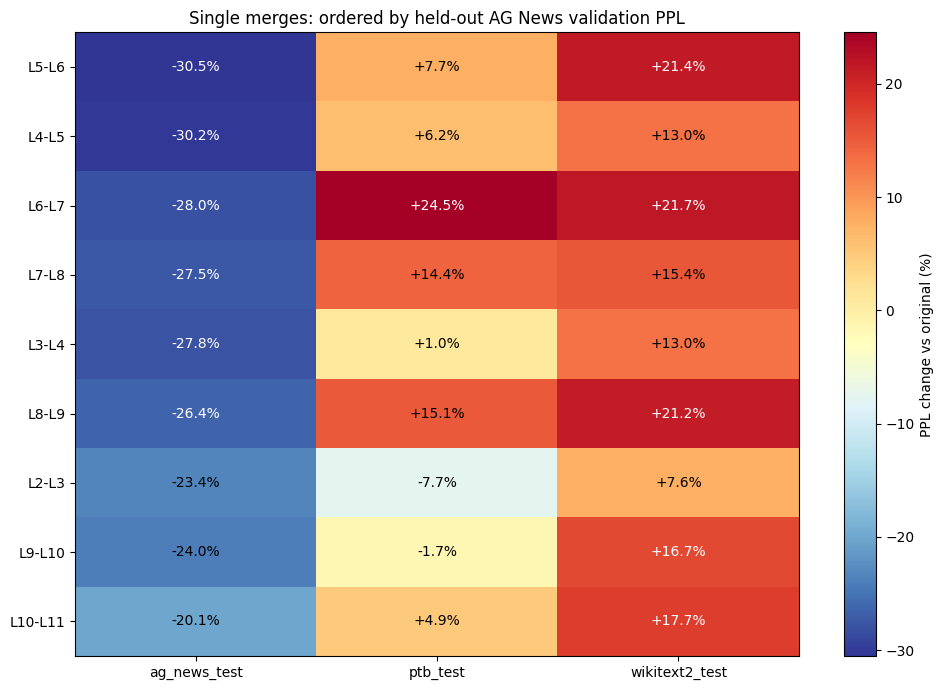

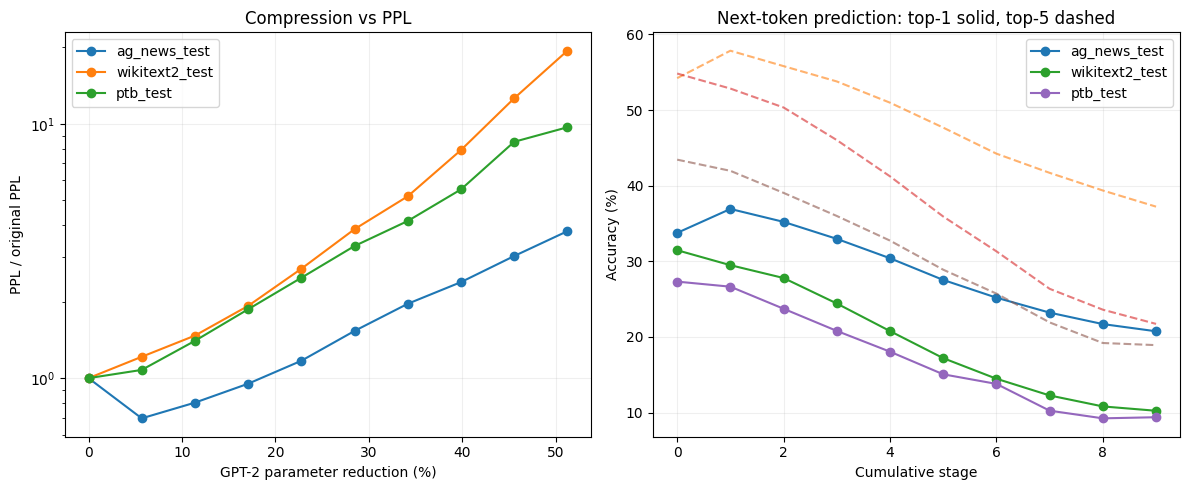

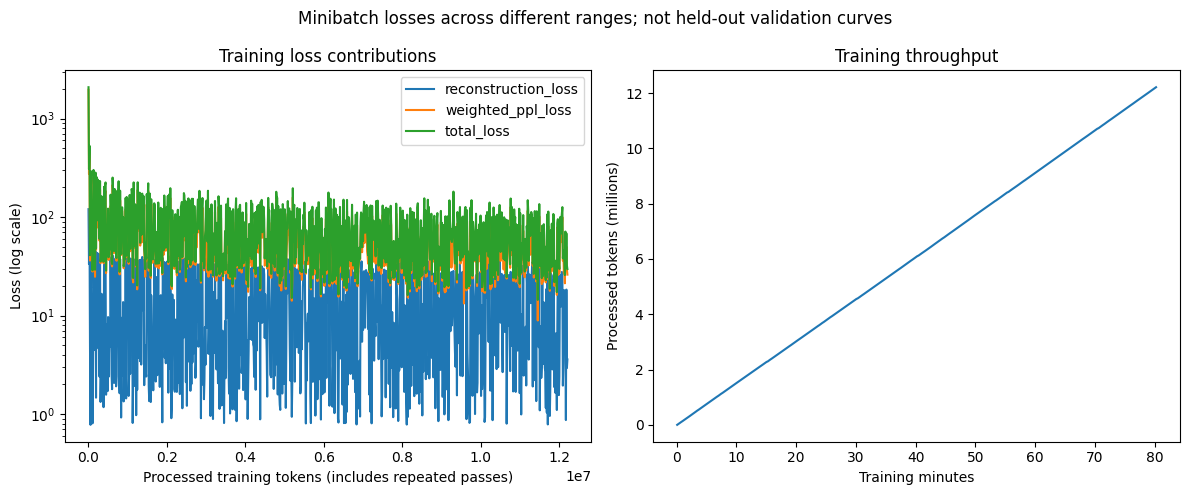

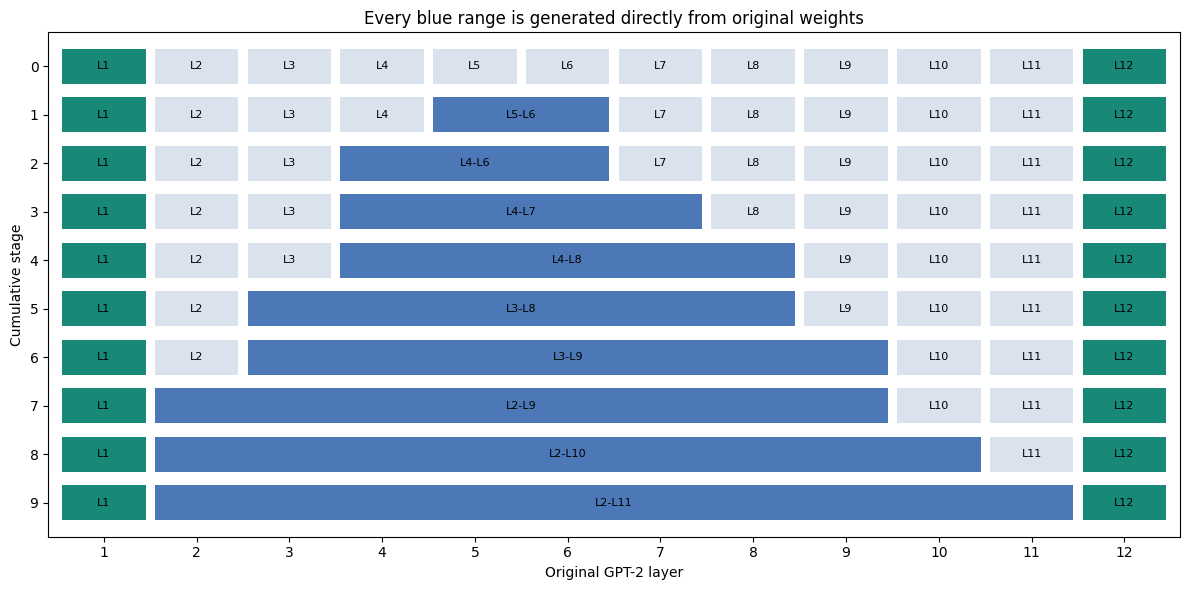

All reports saved to /kaggle/working/gpt2_range_merger_v4_8m_2epochs


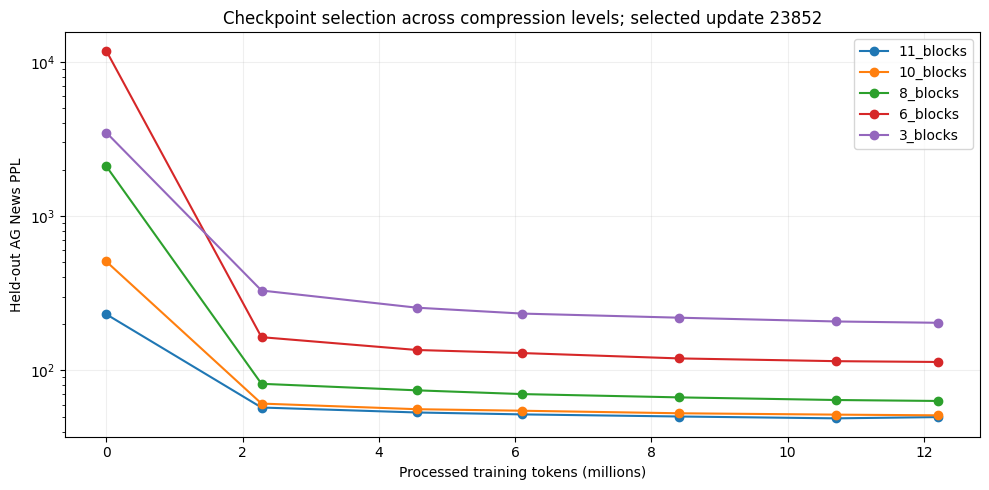

In [10]:
from matplotlib.backends.backend_pdf import PdfPages
with PdfPages(OUTDIR / "experiment_charts.pdf") as pdf:
    def save_chart(fig,name):
        fig.tight_layout()
        fig.savefig(OUTDIR/"plots"/(name+".png"),dpi=170)
        pdf.savefig(fig); plt.show(); plt.close(fig)
    singles = frame[frame.phase=="single"].pivot(index="variant",columns="dataset",values="ppl_change_percent")
    singles = singles.reindex(["single_"+p for p in ranking.pair])
    fig,ax=plt.subplots(figsize=(10,7))
    image=ax.imshow(singles.values,cmap="RdYlBu_r",aspect="auto")
    ax.set_xticks(range(len(singles.columns)),singles.columns)
    ax.set_yticks(range(len(singles)),[v.replace("single_","") for v in singles.index])
    for i in range(len(singles)):
        for j in range(len(singles.columns)):
            rgba=image.cmap(image.norm(singles.iloc[i,j]))
            light=0.2126*rgba[0]+0.7152*rgba[1]+0.0722*rgba[2]
            ax.text(j,i,f"{singles.iloc[i,j]:+.1f}%",ha="center",va="center",color="white" if light<0.45 else "black")
    fig.colorbar(image,ax=ax,label="PPL change vs original (%)")
    ax.set_title("Single merges: ordered by held-out AG News validation PPL")
    save_chart(fig,"single_merge_heatmap")
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for dataset in TEST_IDS:
        data=frame[(frame.dataset==dataset)&(frame.phase!="single")].copy()
        data["stage"]=data["rank"].fillna(0);data=data.sort_values("stage")
        axes[0].plot(data.parameter_reduction_percent,data.ppl_ratio_vs_original,"o-",label=dataset)
        axes[1].plot(data.stage,100*data.top1_accuracy,"o-",label=dataset)
        axes[1].plot(data.stage,100*data.top5_accuracy,"--",alpha=0.6)
    axes[0].set(xlabel="GPT-2 parameter reduction (%)",ylabel="PPL / original PPL",yscale="log",title="Compression vs PPL")
    axes[1].set(xlabel="Cumulative stage",ylabel="Accuracy (%)",title="Next-token prediction: top-1 solid, top-5 dashed")
    for ax in axes:ax.legend();ax.grid(alpha=0.2)
    save_chart(fig,"compression_and_accuracy")
    logs=pd.read_csv(OUTDIR/"merger_training.csv")
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for name in ["reconstruction_loss","weighted_ppl_loss","total_loss"]:
        axes[0].plot(logs.processed_input_tokens,logs[name],label=name)
    axes[0].set(xlabel="Processed training tokens (includes repeated passes)",ylabel="Loss (log scale)",yscale="log",title="Training loss contributions")
    axes[0].legend()
    axes[1].plot(logs.training_minutes,logs.processed_input_tokens/1e6)
    axes[1].set(xlabel="Training minutes",ylabel="Processed tokens (millions)",title="Training throughput")
    fig.suptitle("Minibatch losses across different ranges; not held-out validation curves")
    save_chart(fig,"training_components")
    fig,ax=plt.subplots(figsize=(12,6))
    groups=[[i] for i in range(1,13)]
    all_groups=[groups]
    for record in ranking.to_dict("records"):
        _,groups=union_plan(groups,record["left_layer"]);all_groups.append(groups)
    for stage,groups in enumerate(all_groups):
        for g in groups:
            color="#188977" if g in [[1],[12]] else ("#4d78b8" if len(g)>1 else "#d9e2ed")
            ax.broken_barh([(g[0]-.45,len(g)-.1)],(stage-.36,.72),facecolors=color)
            label=f"L{g[0]}" if len(g)==1 else f"L{g[0]}-L{g[-1]}"
            ax.text((g[0]+g[-1])/2,stage,label,ha="center",va="center",fontsize=8)
    ax.set(xlim=(.4,12.6),ylim=(9.7,-.7),xticks=range(1,13),yticks=range(10),xlabel="Original GPT-2 layer",ylabel="Cumulative stage",title="Every blue range is generated directly from original weights")
    save_chart(fig,"range_progression")

print("All reports saved to",OUTDIR)

# Validation selection curve is separate from noisy training minibatch loss.
history=json.loads((OUTDIR/"validation_history.json").read_text())
fig,ax=plt.subplots(figsize=(10,5))
for name in VALIDATION_PLANS:
    ax.plot([r["processed_input_tokens"]/1e6 for r in history],
            [r["plans"][name]["ppl"] for r in history],"o-",label=name)
selected=json.loads((OUTDIR/"training_summary.json").read_text())["best_validation_update"]
ax.set(xlabel="Processed training tokens (millions)",ylabel="Held-out AG News PPL",yscale="log",
       title=f"Checkpoint selection across compression levels; selected update {selected}")
ax.legend();ax.grid(alpha=0.2);fig.tight_layout()
fig.savefig(OUTDIR/"plots"/"validation_selection.png",dpi=170)
fig.savefig(OUTDIR/"validation_selection.pdf");plt.show();plt.close(fig)
